# 1. Imports
This section contains all the needed packages for the notebook format.

In [1]:
# This notebook lives in `extra/`. Move CWD up to project root.
import os, sys
from pathlib import Path

if Path.cwd().name == "extra":
    os.chdir(Path.cwd().parent)
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"[INFO] Project root: {PROJECT_ROOT}")


[INFO] Project root: c:\Users\andre\Desktop\CV-project-25-26


In [2]:
import json, time, glob, random, gc
import numpy as np
import torch
import lightning as L
import matplotlib.pyplot as plt
import pandas as pd

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
L.seed_everything(SEED, workers=True)

# Colab T4 — drive mount
if torch.cuda.is_available() and torch.cuda.get_device_name(0) == "Tesla T4":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_ROOT = "/content/drive/MyDrive/CV-project-25-26"
        if DRIVE_ROOT not in sys.path:
            sys.path.insert(0, DRIVE_ROOT)
        os.chdir(DRIVE_ROOT)
        print(f"[INFO] Colab T4 — CWD: {os.getcwd()}")
    except Exception as e:
        print(f"[INFO] Not on Colab ({e})")

print("[OK] Environment ready")


W0602 14:15:05.855000 17540 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Seed set to 42


[OK] Environment ready


In [3]:
from src.config import (
    DEVICE,
    ARCH_TYPE,
    FT_BATCH_SIZE,
    NYU_SIZE,
    KITTI_SIZE,
    DATASET_NYU_PATH,
    DATASET_KITTI_PATH,
    DATASET_KITTI_PATH_GT,
    MODEL_SAVE_PATH,
    OUTPUT_DIR,
    IMAGES_DIR,
    JSON_DIR,
)
from src.network    import METERModel
from src.dataset    import NYUDataset, KITTIDataset, build_dataloader
from src.train      import METERFinetune
from src.evaluation import (
    evaluate_depth_model,
    geometric_probing_test_set,
    extract_features,
    features_to_pca,
    evaluate_pixel_weighted,
)
from src.utils      import save_dict_to_json, load_dict_from_json

print("[OK] Project modules imported")


[OK] Project modules imported


# 2. Globals
This section contains useful configuration variables on the whole code.

In [4]:
# ====== USER CONFIG ======
ARCH_NAME = ARCH_TYPE          # "xxs" | "xs" | "s"

# Datasets to include in the analysis
DATASETS = ["nyu", "kitti"]    # set to e.g. ["nyu"] if you only ran NYU

# Variants to compare
VARIANTS = {
    "lejepa": {
        "ckpt_dir" : "finetune_{dataset}",                  # subfolder under MODEL_SAVE_PATH
        "log_name" : "finetune_{dataset}_log",    # CSVLogger 'name' parameter
        "label"    : "LeJEPA-METER",
        "color"    : "#3498db",
    },
    "from_scratch": {
        "ckpt_dir" : "finetune_from_scratch_{dataset}",
        "log_name" : "finetune_from_scratch_{dataset}_log",
        "label"    : "Random init",
        "color"    : "#e67e22",
    },
}

# Number of samples used in visualization grids
NUM_VIS_SAMPLES = 3
# ==========================

ARCH_NAME = ARCH_NAME.lower()
print(f"Architecture : METER-{ARCH_NAME.upper()}")
print(f"Datasets     : {DATASETS}")
print(f"Variants     : {list(VARIANTS.keys())}")

# Output dirs (created if missing)
for p in (OUTPUT_DIR, IMAGES_DIR, JSON_DIR):
    Path(p).mkdir(parents=True, exist_ok=True)
(Path(OUTPUT_DIR) / "csv").mkdir(parents=True, exist_ok=True)


Architecture : METER-XS
Datasets     : ['nyu', 'kitti']
Variants     : ['lejepa', 'from_scratch']


# 3. Utils
This section defines helper functions and utilities used for evaluation and plotting.

In [5]:
def find_checkpoint(ckpt_subdir: str, dataset: str, arch: str) -> Path | None:
    """
    Return the best checkpoint for (dataset, arch) in `ckpt_subdir`.
    Priority:
      1) files containing 'best' AND dataset AND arch  → lowest RMSE in filename wins
      2) any 'best-*' file                             → lowest RMSE in filename wins
      3) last.ckpt                                     → fallback
    """
    import re

    folder = Path(MODEL_SAVE_PATH) / ckpt_subdir
    if not folder.exists():
        return None

    all_ckpts = list(folder.glob("*.ckpt"))
    if not all_ckpts:
        return None

    def extract_rmse(p: Path) -> float:
        """Pull the first float after 'rmse=' or 'val_rmse=' from the filename."""
        m = re.search(r"(?:val[_/]?rmse|rmse)[=_]([\d.]+)", p.stem.lower())
        return float(m.group(1)) if m else float("inf")

    def is_best(p: Path) -> bool:
        return "best" in p.stem.lower()

    def has_dataset(p: Path) -> bool:
        return dataset.lower() in p.stem.lower()

    def has_arch(p: Path) -> bool:
        return arch.lower() in p.stem.lower()

    # Tier 1: best + dataset + arch → pick lowest RMSE
    tier1 = [p for p in all_ckpts if is_best(p) and has_dataset(p) and has_arch(p)]
    if tier1:
        chosen = min(tier1, key=extract_rmse)
        print(f"    [tier1] {chosen.name}  (rmse={extract_rmse(chosen):.4f})")
        return chosen

    # Tier 2: best + dataset (arch may not be in name)
    tier2 = [p for p in all_ckpts if is_best(p) and has_dataset(p)]
    if tier2:
        chosen = min(tier2, key=extract_rmse)
        print(f"    [tier2] {chosen.name}  (rmse={extract_rmse(chosen):.4f})")
        return chosen

    # Tier 3: any best file
    tier3 = [p for p in all_ckpts if is_best(p)]
    if tier3:
        chosen = min(tier3, key=extract_rmse)
        print(f"    [tier3] {chosen.name}  (rmse={extract_rmse(chosen):.4f})")
        return chosen

    # Tier 4: last.ckpt fallback
    last = next((p for p in all_ckpts if p.stem.lower() == "last"), None)
    if last:
        print(f"    [tier4/last] {last.name}")
        return last

    # Tier 5: most recent anything
    fallback = max(all_ckpts, key=lambda p: p.stat().st_mtime)
    print(f"    [tier5/fallback] {fallback.name}")
    return fallback


print("=== CHECKPOINT DISCOVERY ===\n")
checkpoints = {}   # (variant, dataset) -> Path
for variant_key, vinfo in VARIANTS.items():
    for dataset in DATASETS:
        ckpt_subdir = vinfo["ckpt_dir"].format(dataset=dataset)
        ckpt        = find_checkpoint(ckpt_subdir, dataset, ARCH_NAME)
        checkpoints[(variant_key, dataset)] = ckpt
        tag = f"{vinfo['label']:20s} | {dataset:5s}"
        if ckpt is None:
            print(f"  [MISS] {tag} → none in {ckpt_subdir}/")
        else:
            mb = ckpt.stat().st_size / 1e6
            print(f"  [ OK ] {tag} → {ckpt.name}  ({mb:.1f} MB)")

=== CHECKPOINT DISCOVERY ===

    [tier1] best-epoch=45-val_rmse=0.7878-nyu-xs.ckpt  (rmse=0.7878)
  [ OK ] LeJEPA-METER         | nyu   → best-epoch=45-val_rmse=0.7878-nyu-xs.ckpt  (17.7 MB)
    [tier1] best-epoch=49-val_rmse=4.5792-kitti-xs.ckpt  (rmse=4.5792)
  [ OK ] LeJEPA-METER         | kitti → best-epoch=49-val_rmse=4.5792-kitti-xs.ckpt  (17.7 MB)
    [tier1] best-epoch=49-val_rmse=0.8042-nyu-xs.ckpt  (rmse=0.8042)
  [ OK ] Random init          | nyu   → best-epoch=49-val_rmse=0.8042-nyu-xs.ckpt  (17.7 MB)
    [tier1] best-epoch=59-val_rmse=4.5534-kitti-xs.ckpt  (rmse=4.5534)
  [ OK ] Random init          | kitti → best-epoch=59-val_rmse=4.5534-kitti-xs.ckpt  (17.7 MB)



=== DEPTH PREDICTIONS — NYU ===


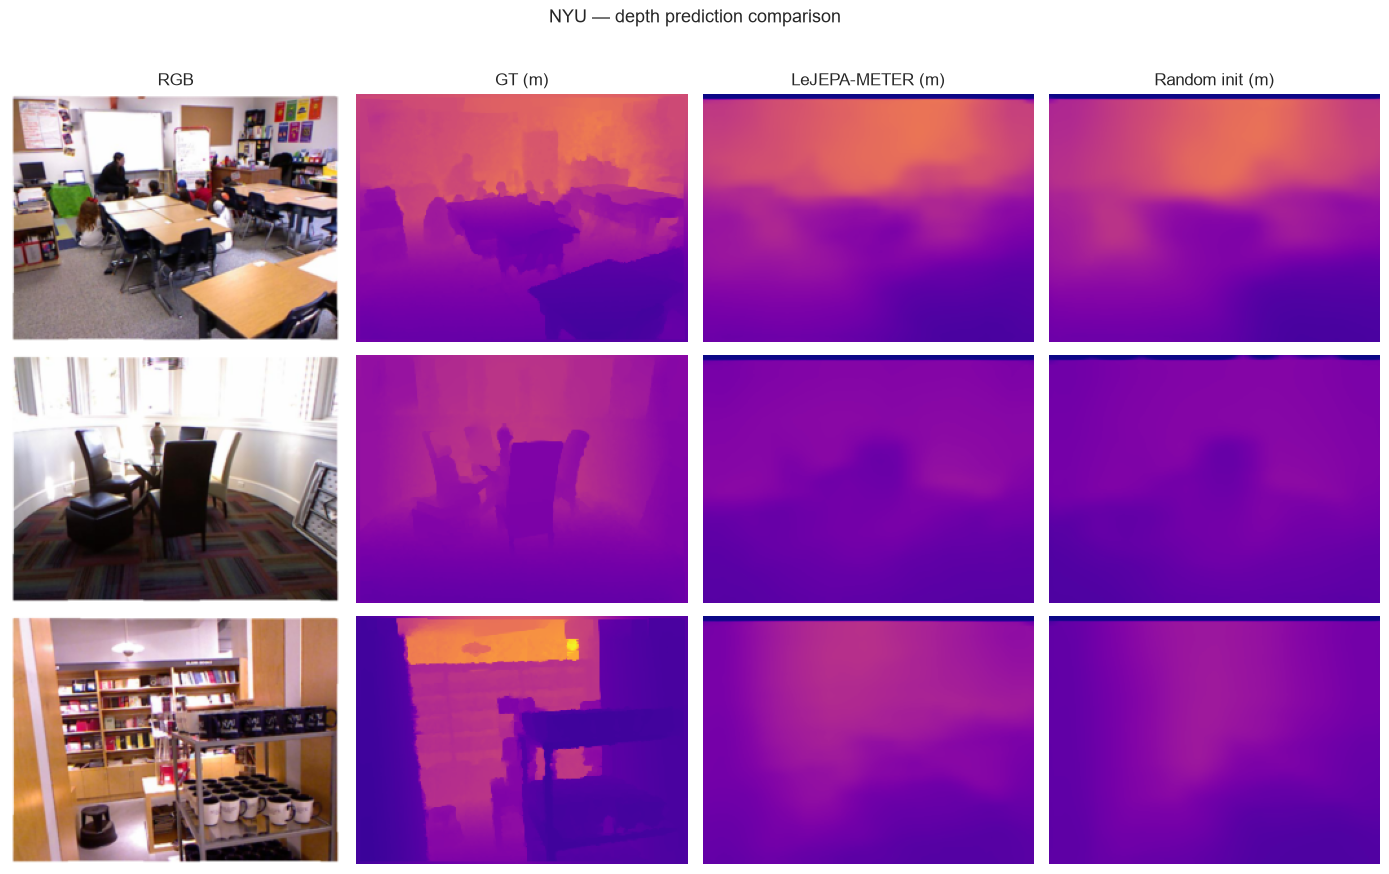

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\compare_predictions_nyu_xs.pdf

=== DEPTH PREDICTIONS — KITTI ===


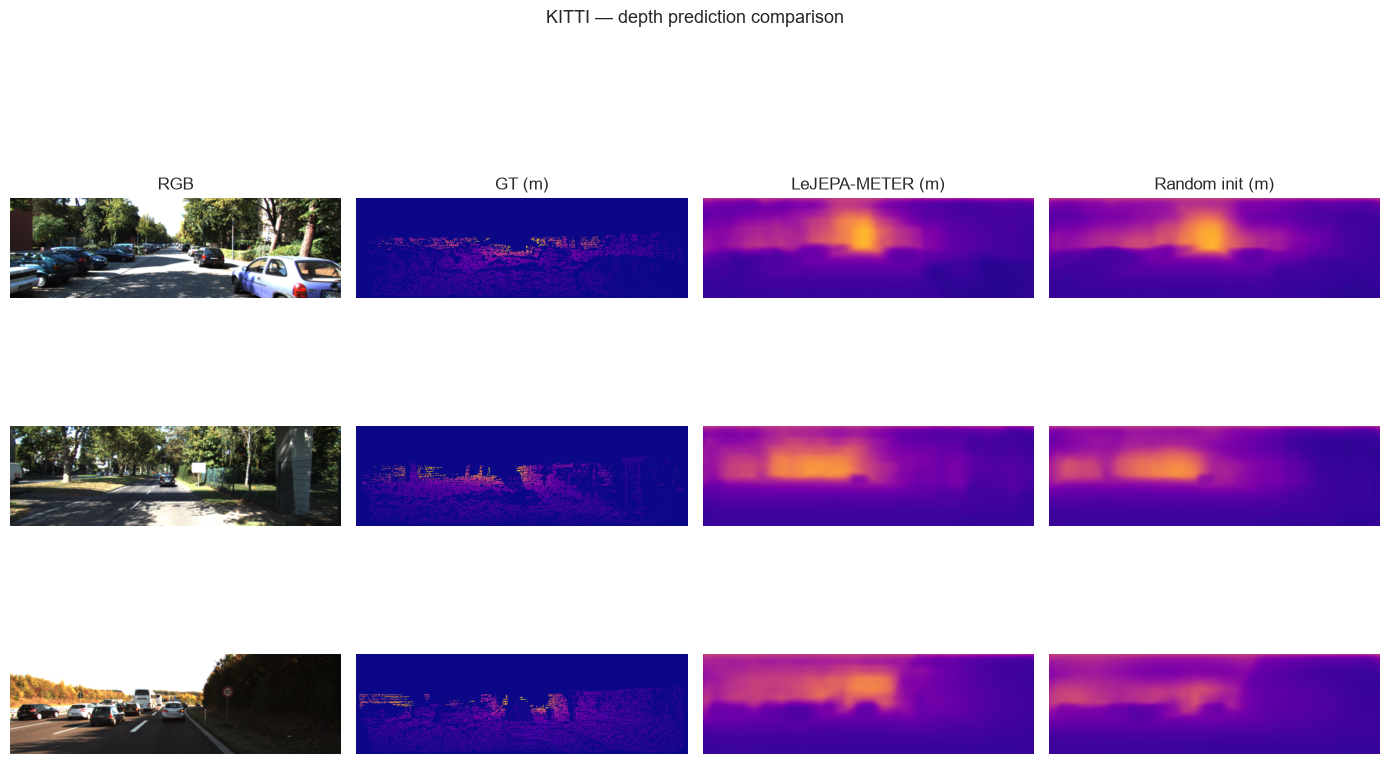

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\compare_predictions_kitti_xs.pdf


In [11]:
def denorm_rgb(rgb_batch):
    """Reverse ImageNet normalization for display."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return (rgb_batch.cpu() * std + mean).clamp(0, 1)


def predict(model, rgb):
    with torch.no_grad():
        return model(rgb.to(DEVICE)).cpu()


for dataset in DATASETS:
    if dataset not in vis_loaders:
        print(f"\n[SKIP {dataset}] no vis loader")
        continue
    variants_with_data = [v for v in VARIANTS if (v, dataset) in models]
    if not variants_with_data:
        print(f"\n[SKIP {dataset}] no models loaded")
        continue

    print(f"\n=== DEPTH PREDICTIONS — {dataset.upper()} ===")

    batch = next(iter(vis_loaders[dataset]))
    rgb, depth_gt = batch
    rgb_show = denorm_rgb(rgb)

    # Unit conversion (NYU GT in cm → m)
    if dataset == "nyu":
        scale, unit, vmax = 1/100.0, "m", 10.0
    else:
        scale, unit, vmax = 1.0, "m", 80.0

    gt_m = depth_gt.cpu() * scale

    preds = {}
    for v in variants_with_data:
        pred = predict(models[(v, dataset)], rgb).cpu() * scale
        preds[v] = pred

    n_samples = rgb.shape[0]
    n_cols = 2 + len(variants_with_data)   # RGB | GT | variant1 | variant2 ...
    fig, axes = plt.subplots(n_samples, n_cols, figsize=(3.5 * n_cols, 3.0 * n_samples))
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_m[i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
        axes[i, 1].set_title(f"GT ({unit})" if i == 0 else ""); axes[i, 1].axis("off")

        for k, v in enumerate(variants_with_data):
            axes[i, 2 + k].imshow(preds[v][i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
            axes[i, 2 + k].set_title(f"{VARIANTS[v]['label']} ({unit})" if i == 0 else "")
            axes[i, 2 + k].axis("off")

    plt.suptitle(f"{dataset.upper()} — depth prediction comparison", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = Path(IMAGES_DIR) / f"compare_predictions_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")


In [15]:
def benchmark(model, device, img_size, warmup=10, runs=50):
    model.eval().to(device)
    dummy = torch.randn(1, *img_size).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    params_m = n_params / 1e6

    def sync():
        if device.type == "cuda":  torch.cuda.synchronize()
        elif device.type == "mps": torch.mps.synchronize()

    with torch.no_grad():
        for _ in range(warmup):
            _ = model(dummy)
        sync()
        t0 = time.time()
        for _ in range(runs):
            _ = model(dummy)
        sync()
    elapsed = time.time() - t0
    latency_ms = elapsed / runs * 1000.0
    fps = 1000.0 / latency_ms if latency_ms > 0 else float("inf")
    return {"params_m": params_m, "latency_ms": latency_ms, "fps": fps}


print("=== EFFICIENCY BENCHMARK ===")
img_size_nyu   = (3, NYU_SIZE[0], NYU_SIZE[1])
img_size_kitti = (3, KITTI_SIZE[0], KITTI_SIZE[1])

# Use any loaded model — they share the architecture
sample_model = next(iter(models.values())) if models else METERFinetune(arch_type=ARCH_NAME)

eff_nyu   = benchmark(sample_model, DEVICE, img_size_nyu)   if "nyu"   in DATASETS else None
eff_kitti = benchmark(sample_model, DEVICE, img_size_kitti) if "kitti" in DATASETS else None

if eff_nyu:
    print(f"\n[NYU   {img_size_nyu}]   "
          f"params={eff_nyu['params_m']:.3f}M  "
          f"latency={eff_nyu['latency_ms']:.2f} ms  "
          f"fps={eff_nyu['fps']:.1f}")
if eff_kitti:
    print(f"[KITTI {img_size_kitti}] "
          f"params={eff_kitti['params_m']:.3f}M  "
          f"latency={eff_kitti['latency_ms']:.2f} ms  "
          f"fps={eff_kitti['fps']:.1f}")

efficiency = {"nyu": eff_nyu, "kitti": eff_kitti}


=== EFFICIENCY BENCHMARK ===

[NYU   (3, 192, 256)]   params=1.450M  latency=13.38 ms  fps=74.7
[KITTI (3, 192, 636)] params=1.450M  latency=14.26 ms  fps=70.1


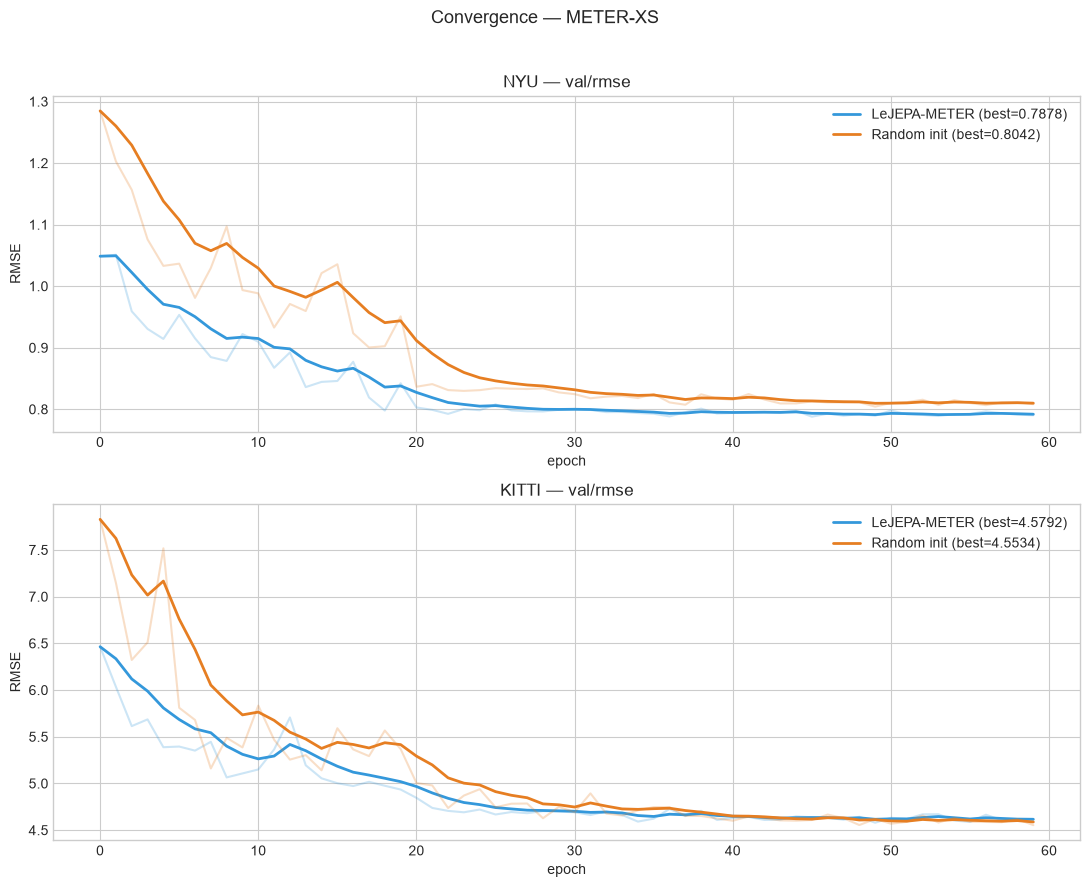


[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\convergence_overlay_xs.pdf


In [16]:
def smooth(arr, alpha=0.7):
    out, ema = [], None
    for v in arr:
        ema = v if ema is None else alpha * ema + (1 - alpha) * v
        out.append(ema)
    return out


def per_epoch(df, col):
    if col not in df.columns:
        return None, None
    s = (df.groupby("epoch")[col]
            .apply(lambda x: x.dropna().iloc[-1] if x.dropna().shape[0] else np.nan)
            .dropna())
    return s.index.values, s.values


def load_logger_df(name_pattern: str):
    matches = list(Path(OUTPUT_DIR).glob(f"{name_pattern}/version_*/metrics.csv"))
    if not matches:
        matches = list(Path(OUTPUT_DIR).rglob("metrics.csv"))
        matches = [m for m in matches if name_pattern in str(m)]
    if not matches:
        return None
    matches.sort(key=lambda p: p.stat().st_mtime)
    frames = []
    for p in matches:
        try:
            frames.append(pd.read_csv(p))
        except Exception:
            pass
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True)
    if "epoch" in df.columns:
        df = (df.sort_values("step", na_position="last")
                .groupby("epoch", as_index=False)
                .last()
                .sort_values("epoch")
                .reset_index(drop=True))
    return df


datasets_with_data = [d for d in DATASETS if any((v, d) in results for v in VARIANTS)]
if not datasets_with_data:
    print("[SKIP] no datasets have results")
else:
    fig, axes = plt.subplots(len(datasets_with_data), 1,
                              figsize=(11, 4.5 * len(datasets_with_data)),
                              squeeze=False)
    axes = axes.flatten()

    for r, dataset in enumerate(datasets_with_data):
        ax = axes[r]
        plotted = 0
        for variant_key, vinfo in VARIANTS.items():
            log_name = vinfo["log_name"].format(dataset=dataset)

            # ✅ NOW USING load_logger_df — not find_logger_csv + pd.read_csv
            df = load_logger_df(log_name)
            if df is None:
                print(f"  [MISS] {vinfo['label']} | {dataset} — no CSV under {log_name}")
                continue

            ep, v = per_epoch(df, "val/rmse")
            if ep is None or len(ep) == 0:
                continue
            v_smooth = smooth(v, 0.7)
            ax.plot(ep, v,        color=vinfo["color"], alpha=0.25)
            ax.plot(ep, v_smooth, color=vinfo["color"], linewidth=2.0,
                    label=f"{vinfo['label']} (best={min(v):.4f})")
            plotted += 1

        ax.set_title(f"{dataset.upper()} — val/rmse")
        ax.set_xlabel("epoch"); ax.set_ylabel("RMSE")
        if plotted:
            ax.legend(loc="best")
        else:
            ax.text(0.5, 0.5, "no CSV logs found", ha="center", va="center",
                    transform=ax.transAxes)

    plt.suptitle(f"Convergence — METER-{ARCH_NAME.upper()}", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    conv_path = Path(IMAGES_DIR) / f"convergence_overlay_{ARCH_NAME}.pdf"
    plt.savefig(conv_path, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"\n[OK] Saved → {conv_path}")

In [17]:
def first_epoch_reaching(epochs, values, threshold):
    """First epoch at which values[i] <= threshold."""
    for ep, v in zip(epochs, values):
        if v <= threshold:
            return int(ep)
    return None

print("=== CONVERGENCE SPEED QUANTIFICATION ===\n")
conv_rows = []

for dataset in DATASETS:
    for variant_key, vinfo in VARIANTS.items():
        log_name = vinfo["log_name"].format(dataset=dataset)
        df = load_logger_df(log_name)
        if df is None:
            continue

        ep, v = per_epoch(df, "val/rmse")
        if ep is None or len(ep) == 0:
            continue

        best_idx   = int(np.argmin(v))
        best_rmse  = float(v[best_idx])
        best_epoch = int(ep[best_idx])

        def at_epoch(target):
            mask = (ep == target)
            return float(v[mask][0]) if mask.any() else float("nan")

        ep_to_near = first_epoch_reaching(ep, v, best_rmse * 1.05)

        conv_rows.append({
            "Dataset"           : dataset.upper(),
            "Variant"           : vinfo["label"],
            "Best RMSE"         : f"{best_rmse:.4f}",
            "Best epoch"        : best_epoch,
            "RMSE @ ep 5"       : f"{at_epoch(5):.4f}",
            "RMSE @ ep 10"      : f"{at_epoch(10):.4f}",
            "RMSE @ ep 20"      : f"{at_epoch(20):.4f}",
            "RMSE @ ep 30"      : f"{at_epoch(30):.4f}",
            "Epoch to 1.05×best": ep_to_near if ep_to_near is not None else "—",
        })

if conv_rows:
    conv_df = pd.DataFrame(conv_rows)
    print(conv_df.to_string(index=False))
    out_csv = Path(OUTPUT_DIR) / "csv" / f"convergence_speed_{ARCH_NAME}.csv"
    conv_df.to_csv(out_csv, index=False)
    print(f"\n[OK] Saved → {out_csv}")

    print("\n=== CONVERGENCE HEADLINE ===")
    for dataset in DATASETS:
        rows = [r for r in conv_rows if r["Dataset"] == dataset.upper()]
        if len(rows) < 2:
            continue
        lej = next((r for r in rows if "LeJEPA" in r["Variant"]), None)
        rnd = next((r for r in rows if "Random" in r["Variant"]), None)
        if lej and rnd:
            try:
                lej_e10  = float(lej["RMSE @ ep 10"])
                rnd_e10  = float(rnd["RMSE @ ep 10"])
                gain_e10 = (rnd_e10 - lej_e10) / rnd_e10 * 100
                verdict  = "✅ faster" if gain_e10 > 1 else ("⚠️ slower" if gain_e10 < -1 else "≈ same")
                print(f"  {dataset.upper():6s}  RMSE @ ep10: LeJEPA={lej_e10:.3f} vs "
                      f"Random={rnd_e10:.3f}  → {verdict} ({gain_e10:+.1f}%)")
            except Exception:
                pass
else:
    print("[SKIP] No convergence CSVs found")

=== CONVERGENCE SPEED QUANTIFICATION ===

Dataset      Variant Best RMSE  Best epoch RMSE @ ep 5 RMSE @ ep 10 RMSE @ ep 20 RMSE @ ep 30  Epoch to 1.05×best
    NYU LeJEPA-METER    0.7878          45      0.9533       0.9096       0.8029       0.8004                  17
    NYU  Random init    0.8042          49      1.0365       0.9883       0.8365       0.8245                  20
  KITTI LeJEPA-METER    4.5792          49      5.3948       5.1494       4.8456       4.6914                  21
  KITTI  Random init    4.5534          59      5.8097       5.8333       5.0047       4.6916                  22

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\csv\convergence_speed_xs.csv

=== CONVERGENCE HEADLINE ===
  NYU     RMSE @ ep10: LeJEPA=0.910 vs Random=0.988  → ✅ faster (+8.0%)
  KITTI   RMSE @ ep10: LeJEPA=5.149 vs Random=5.833  → ✅ faster (+11.7%)


# 4. Data
This section loads the test sets and sets up dataloaders for quantitative and qualitative evaluation.

In [6]:
print("=== BUILDING TEST DATALOADERS ===\n")

test_loaders, vis_loaders = {}, {}

if "nyu" in DATASETS:
    try:
        nyu_test = NYUDataset(
            path    = DATASET_NYU_PATH,
            mode    = "finetune",
            split   = "test",
            kaggle  = False,
            augment = False,                  # ← critical: no aug at eval
        )
        if len(nyu_test) == 0:
            print("[WARN] NYU test set is empty — skipping NYU")
        else:
            test_loaders["nyu"] = build_dataloader(
                nyu_test, batch_size=FT_BATCH_SIZE, shuffle=False, drop_last=False)
            vis_loaders["nyu"]  = build_dataloader(
                nyu_test, batch_size=NUM_VIS_SAMPLES, shuffle=True, drop_last=True)
            print(f"[OK] NYU   loader — {len(nyu_test)} samples")
    except Exception as e:
        print(f"[FAIL] NYU build failed: {e}")

if "kitti" in DATASETS:
    try:
        kitti_rgb_root = Path(DATASET_KITTI_PATH)    / "rgb"
        kitti_gt_root  = Path(DATASET_KITTI_PATH_GT) / "depth"

        print(f"[DEBUG] KITTI RGB root: {kitti_rgb_root} (exists: {kitti_rgb_root.exists()})")
        print(f"[DEBUG] KITTI GT  root: {kitti_gt_root} (exists: {kitti_gt_root.exists()})")

        if not kitti_rgb_root.exists() or not kitti_gt_root.exists():
            raise FileNotFoundError(f"KITTI paths missing")

        kitti_test = KITTIDataset(
            path    = kitti_rgb_root,
            gt_root = kitti_gt_root,
            mode    = "finetune",
            split   = "val",
            augment = False,                  # ← critical: no aug at eval
        )
        if len(kitti_test) == 0:
            print("[WARN] KITTI val set is empty")
        else:
            test_loaders["kitti"] = build_dataloader(
                kitti_test, batch_size=16, shuffle=False, drop_last=False)
            vis_loaders["kitti"]  = build_dataloader(
                kitti_test, batch_size=NUM_VIS_SAMPLES, shuffle=True, drop_last=True)
            print(f"[OK] KITTI loader — {len(kitti_test)} samples")
    except Exception as e:
        print(f"[FAIL] KITTI build failed: {e}")
        import traceback; traceback.print_exc()

print(f"\nAvailable test loaders : {list(test_loaders.keys())}")
print(f"Available vis loaders  : {list(vis_loaders.keys())}")

=== BUILDING TEST DATALOADERS ===


[INFO] NYUDataset — mode=finetune, split=test, kaggle=False
[INFO] NYUDataset — 654 samples  (format=mat)
[INFO] DataLoader — batch=64  workers=4  shuffle=False  pin_memory=True
[INFO] DataLoader — batch=3  workers=4  shuffle=True  pin_memory=True
[OK] NYU   loader — 654 samples
[DEBUG] KITTI RGB root: C:\Users\andre\Desktop\CV-project-25-26\data\raw\kitti\rgb (exists: True)
[DEBUG] KITTI GT  root: C:\Users\andre\Desktop\CV-project-25-26\data\raw\kitti\depth (exists: True)

[INFO] KITTIDataset — mode=finetune, split=val
[INFO] KITTIDataset — 3347 samples
[INFO] DataLoader — batch=16  workers=4  shuffle=False  pin_memory=True
[INFO] DataLoader — batch=3  workers=4  shuffle=True  pin_memory=True
[OK] KITTI loader — 3347 samples

Available test loaders : ['nyu', 'kitti']
Available vis loaders  : ['nyu', 'kitti']


# 5. Network
Since training is completed and we evaluate pre-trained checkpoints, the network structure is instantiated dynamically when loading the saved models under the Evaluation section.

# 6. Train
This is an evaluation and comparative analysis notebook; no training is conducted here. Training elements are located in `main_final.ipynb`.

# 7. Evaluation
This section contains the core comparative analysis, evaluation loops, zero-shot and post-finetuning geometric probing, predictions display, and benchmarking results.

In [7]:
import random as _r

print("=== EVALUATION LOOP ===\n")

# Determinism setup (eliminates residual GPU non-determinism)
def _set_seeds(seed=42):
    _r.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False


results = {}
models  = {}

for (variant_key, dataset), ckpt in checkpoints.items():
    label = VARIANTS[variant_key]["label"]
    tag   = f"[{label} | {dataset.upper()}]"

    if ckpt is None:
        print(f"{tag} SKIP — no checkpoint")
        continue
    if dataset not in test_loaders:
        print(f"{tag} SKIP — no test loader for {dataset}")
        continue

    # Reset RNG state before each model load + eval — full determinism
    _set_seeds(42)

    print(f"{tag} loading {ckpt.name} …")
    try:
        model = METERFinetune.load_from_checkpoint(
            str(ckpt),
            dataset_name=dataset,
        ).to(DEVICE)
        model.eval()
    except Exception as e:
        print(f"{tag} FAIL — could not load: {e}")
        continue

    train_time_sec = float(getattr(model, "total_train_time", 0.0) or 0.0)

    print(f"{tag} evaluating on {len(test_loaders[dataset].dataset)} samples …")
    t0 = time.time()
    metrics = evaluate_pixel_weighted(
        model        = model,
        dataloader   = test_loaders[dataset],
        device       = DEVICE,
        dataset_name = dataset,
    )
    elapsed = time.time() - t0
    print(f"{tag} done in {elapsed:.1f} s — "
          f"RMSE={metrics['RMSE']:.4f}  AbsRel={metrics['AbsRel']:.4f}  Delta1={metrics['Delta1']:.4f}")

    results[(variant_key, dataset)] = {
        **metrics,
        "train_time_sec": train_time_sec,
        "eval_time_sec" : elapsed,
        "checkpoint"    : str(ckpt),
        "variant"       : variant_key,
        "dataset"       : dataset,
        "arch"          : ARCH_NAME,
    }
    models[(variant_key, dataset)] = model

print(f"\nEvaluated configurations: {len(results)} / {len(checkpoints)}")
print("Note: pixel-weighted aggregation, no augmentation, seeded RNG → deterministic across runs")

=== EVALUATION LOOP ===

[LeJEPA-METER | NYU] loading best-epoch=45-val_rmse=0.7878-nyu-xs.ckpt …

[INFO] Initializing METERFinetune — dataset: nyu

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[LOAD] last.ckpt
       Loaded           : 250 layers
       Missing (rand)   : 0 layers
       Unexpected (skip): 0 layers
[INFO] SSL encoder loaded successfully from C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\ssl_nyu\last.ckpt
[INFO] METERFinetune ready
[LeJEPA-METER | NYU] evaluating on 654 samples …
[LeJEPA-METER | NYU] done in 8.6 s — RMSE=0.8522  AbsRel=0.1952  Delta1=0.6971
[LeJEPA-METER | KITTI] loading best-epoch=49-val_rmse=4.5792-kitti-xs.ckpt …

[INFO] Initializing METERFinetune — dataset: kitti

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[LOAD] last.ckpt
       Loaded           : 250 layers
       Missing (rand)   : 0 layers
       Unexpected (skip): 0 layers
[INFO] SSL enco

=== ZERO-SHOT GEOMETRIC PROBING (pre fine-tuning) ===


[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760

--- NYU — SSL ckpt: last.ckpt ---

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[INFO] SSL encoder loaded — missing=0, unexpected=0


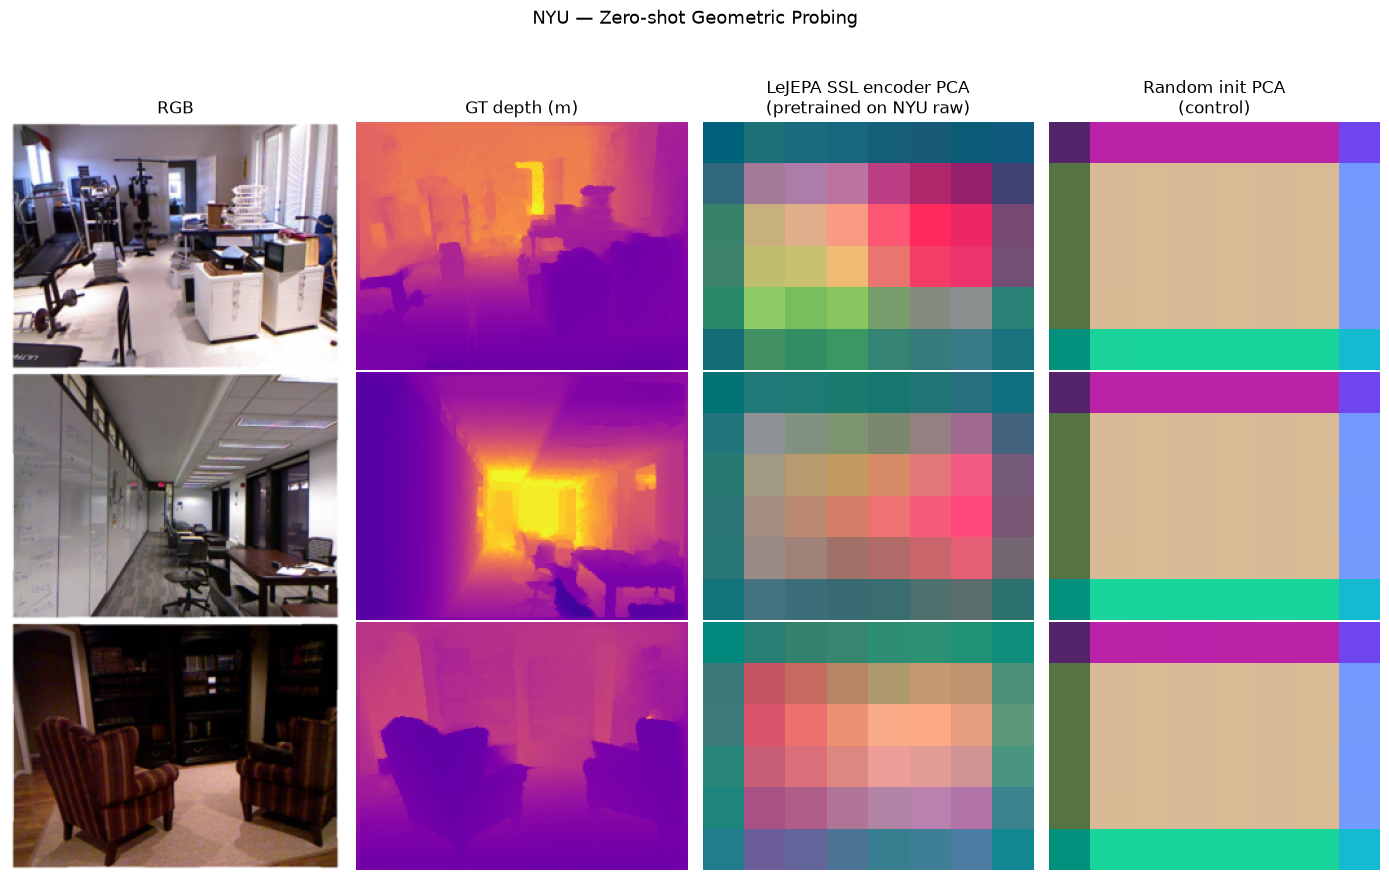

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\zero_shot_probing_nyu_xs.pdf

--- KITTI — SSL ckpt: last.ckpt ---

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[INFO] SSL encoder loaded — missing=0, unexpected=0


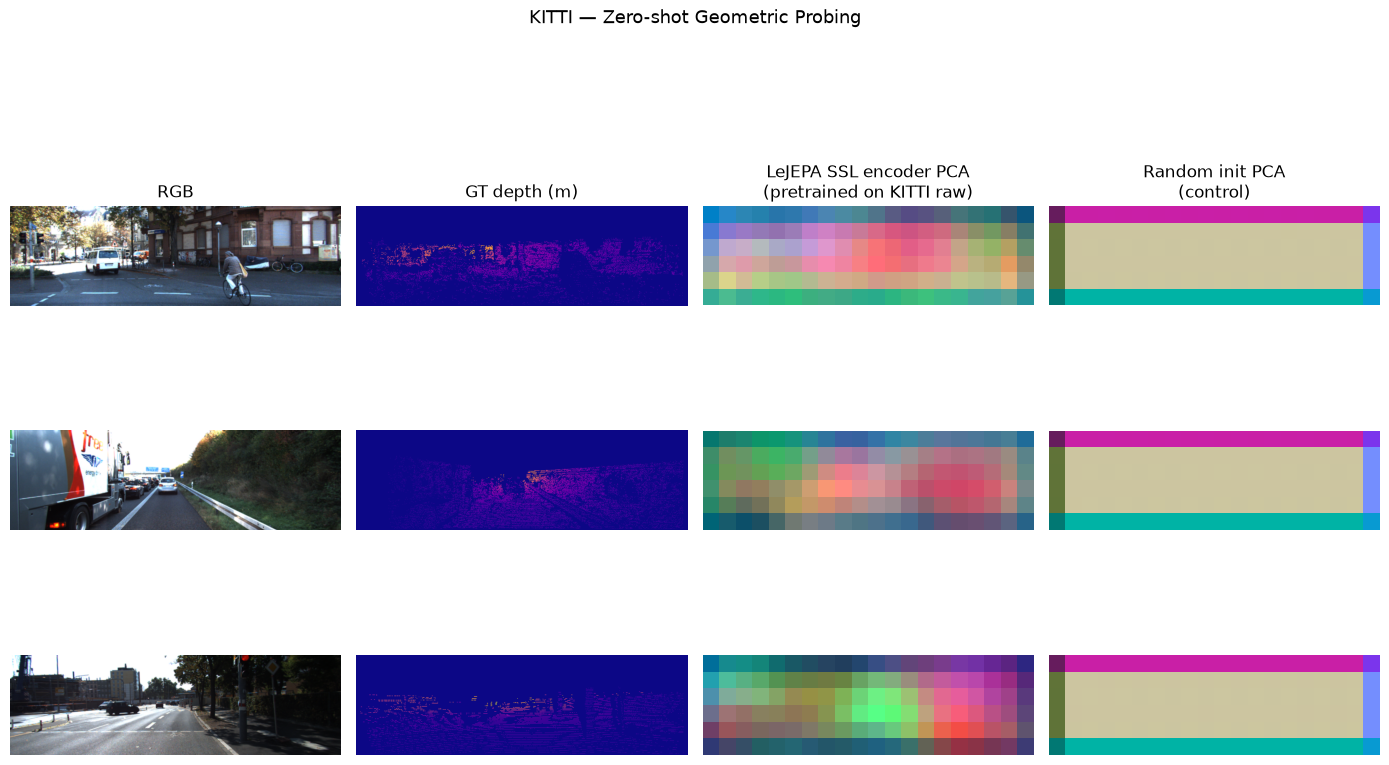

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\zero_shot_probing_kitti_xs.pdf


In [8]:
print("=== ZERO-SHOT GEOMETRIC PROBING (pre fine-tuning) ===\n")


def denorm_rgb_local(batch):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)


def find_ssl_ckpt(dataset: str) -> Path | None:
    """Try several plausible locations for the per-dataset SSL ckpt."""
    candidates = [
        Path(MODEL_SAVE_PATH) / f"ssl_{dataset}" / "last.ckpt",
        Path(MODEL_SAVE_PATH) / f"ssl_{dataset}" / "best.ckpt",
        Path(MODEL_SAVE_PATH) / "ssl" / "last.ckpt",   # legacy fallback (NYU only)
    ]
    for c in candidates:
        if c.exists():
            return c
    # any best-*.ckpt as last resort
    folder = Path(MODEL_SAVE_PATH) / f"ssl_{dataset}"
    if folder.exists():
        best_files = sorted(folder.glob("best-*.ckpt"),
                            key=lambda p: p.stat().st_mtime, reverse=True)
        if best_files:
            return best_files[0]
    return None


# Random encoder shared across datasets (it's truly random, no dataset dependency)
random_encoder_model = METERModel(arch_type=ARCH_NAME).to(DEVICE)
random_encoder_model.eval()

for dataset in DATASETS:
    if dataset not in vis_loaders:
        print(f"[SKIP {dataset}] no vis loader")
        continue

    ssl_ckpt_path = find_ssl_ckpt(dataset)
    if ssl_ckpt_path is None:
        print(f"[SKIP {dataset}] no SSL ckpt found under ssl_{dataset}/")
        continue

    print(f"\n--- {dataset.upper()} — SSL ckpt: {ssl_ckpt_path.name} ---")

    # Load SSL encoder weights into a fresh METER (no fine-tuning, no decoder use)
    ssl_encoder_model = METERModel(arch_type=ARCH_NAME).to(DEVICE)
    ckpt = torch.load(ssl_ckpt_path, map_location="cpu", weights_only=False)
    state = ckpt.get("state_dict", ckpt)
    enc_state = {}
    for k, v in state.items():
        if k.startswith("encoder."):
            enc_state[k[len("encoder."):]] = v
        elif k.startswith("model.encoder."):
            enc_state[k[len("model.encoder."):]] = v
    msg = ssl_encoder_model.encoder.load_state_dict(enc_state, strict=False)
    print(f"[INFO] SSL encoder loaded — missing={len(msg.missing_keys)}, "
          f"unexpected={len(msg.unexpected_keys)}")
    ssl_encoder_model.eval()

    batch = next(iter(vis_loaders[dataset]))
    rgb, depth_gt = batch
    rgb_show = denorm_rgb_local(rgb)

    gt_scale = 1/100.0 if dataset == "nyu" else 1.0
    gt_unit  = "m"
    gt_vmax  = 10.0 if dataset == "nyu" else 80.0
    gt_show  = (depth_gt.cpu() * gt_scale)

    n = rgb.shape[0]
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.0 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_show[i, 0].numpy(), cmap="plasma", vmin=0, vmax=gt_vmax)
        axes[i, 1].set_title(f"GT depth ({gt_unit})" if i == 0 else "")
        axes[i, 1].axis("off")

        feat_ssl = extract_features(ssl_encoder_model, rgb[i:i+1].to(DEVICE), DEVICE)
        axes[i, 2].imshow(features_to_pca(feat_ssl))
        axes[i, 2].set_title(f"LeJEPA SSL encoder PCA\n(pretrained on {dataset.upper()} raw)"
                             if i == 0 else "")
        axes[i, 2].axis("off")

        feat_rnd = extract_features(random_encoder_model, rgb[i:i+1].to(DEVICE), DEVICE)
        axes[i, 3].imshow(features_to_pca(feat_rnd))
        axes[i, 3].set_title("Random init PCA\n(control)" if i == 0 else "")
        axes[i, 3].axis("off")

    plt.suptitle(f"{dataset.upper()} — Zero-shot Geometric Probing", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    out = Path(IMAGES_DIR) / f"zero_shot_probing_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")

In [9]:
print("=== SAVING METRICS JSON ===\n")
for (variant_key, dataset), data in results.items():
    json_path = Path(JSON_DIR) / f"results_{variant_key}_{dataset}_{ARCH_NAME}.json"
    save_dict_to_json(data, json_path)


=== SAVING METRICS JSON ===

[INFO] JSON saved → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_lejepa_nyu_xs.json
[INFO] JSON saved → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_lejepa_kitti_xs.json
[INFO] JSON saved → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_from_scratch_nyu_xs.json
[INFO] JSON saved → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_from_scratch_kitti_xs.json


=== COMPARATIVE BAR CHART ===


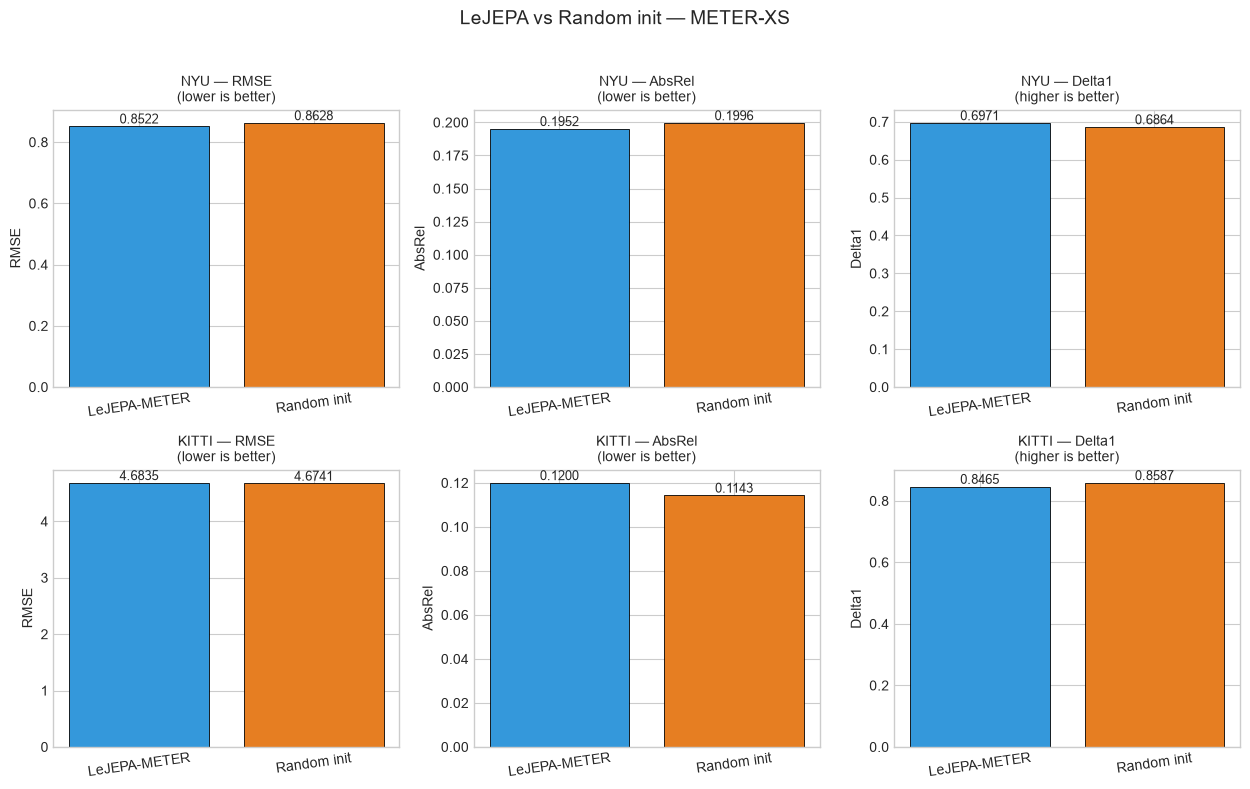


[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\compare_metrics_grid_xs.pdf


In [10]:
print("=== COMPARATIVE BAR CHART ===")
if not results:
    print("[SKIP] no results to plot")
else:
    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

    metric_specs = [
        ("RMSE",   "lower is better"),
        ("AbsRel", "lower is better"),
        ("Delta1", "higher is better"),
    ]

    datasets_present = [d for d in DATASETS if any((v, d) in results for v in VARIANTS)]
    n_rows = len(datasets_present)
    n_cols = len(metric_specs)
    if n_rows == 0:
        print("[SKIP] no dataset has any results")
    else:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4.0 * n_rows))
        if n_rows == 1:
            axes = np.expand_dims(axes, axis=0)

        for r, dataset in enumerate(datasets_present):
            variants_with_data = [v for v in VARIANTS if (v, dataset) in results]
            labels = [VARIANTS[v]["label"] for v in variants_with_data]
            colors = [VARIANTS[v]["color"] for v in variants_with_data]

            for c, (metric, direction) in enumerate(metric_specs):
                ax = axes[r, c]
                values = [results[(v, dataset)][metric] for v in variants_with_data]
                bars = ax.bar(labels, values, color=colors, edgecolor="black", linewidth=0.6)
                for bar, val in zip(bars, values):
                    h = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2, h, f"{val:.4f}",
                            ha="center", va="bottom", fontsize=9)
                ax.set_title(f"{dataset.upper()} — {metric}\n({direction})", fontsize=10)
                ax.set_ylabel(metric)
                ax.tick_params(axis="x", rotation=8)

        plt.suptitle(f"LeJEPA vs Random init — METER-{ARCH_NAME.upper()}", fontsize=14)
        plt.tight_layout(rect=[0, 0, 1, 0.96])

        bar_path = Path(IMAGES_DIR) / f"compare_metrics_grid_{ARCH_NAME}.pdf"
        plt.savefig(bar_path, dpi=140, bbox_inches="tight")
        plt.show()
        print(f"\n[OK] Saved → {bar_path}")



=== DIFFERENCE MAPS — NYU ===


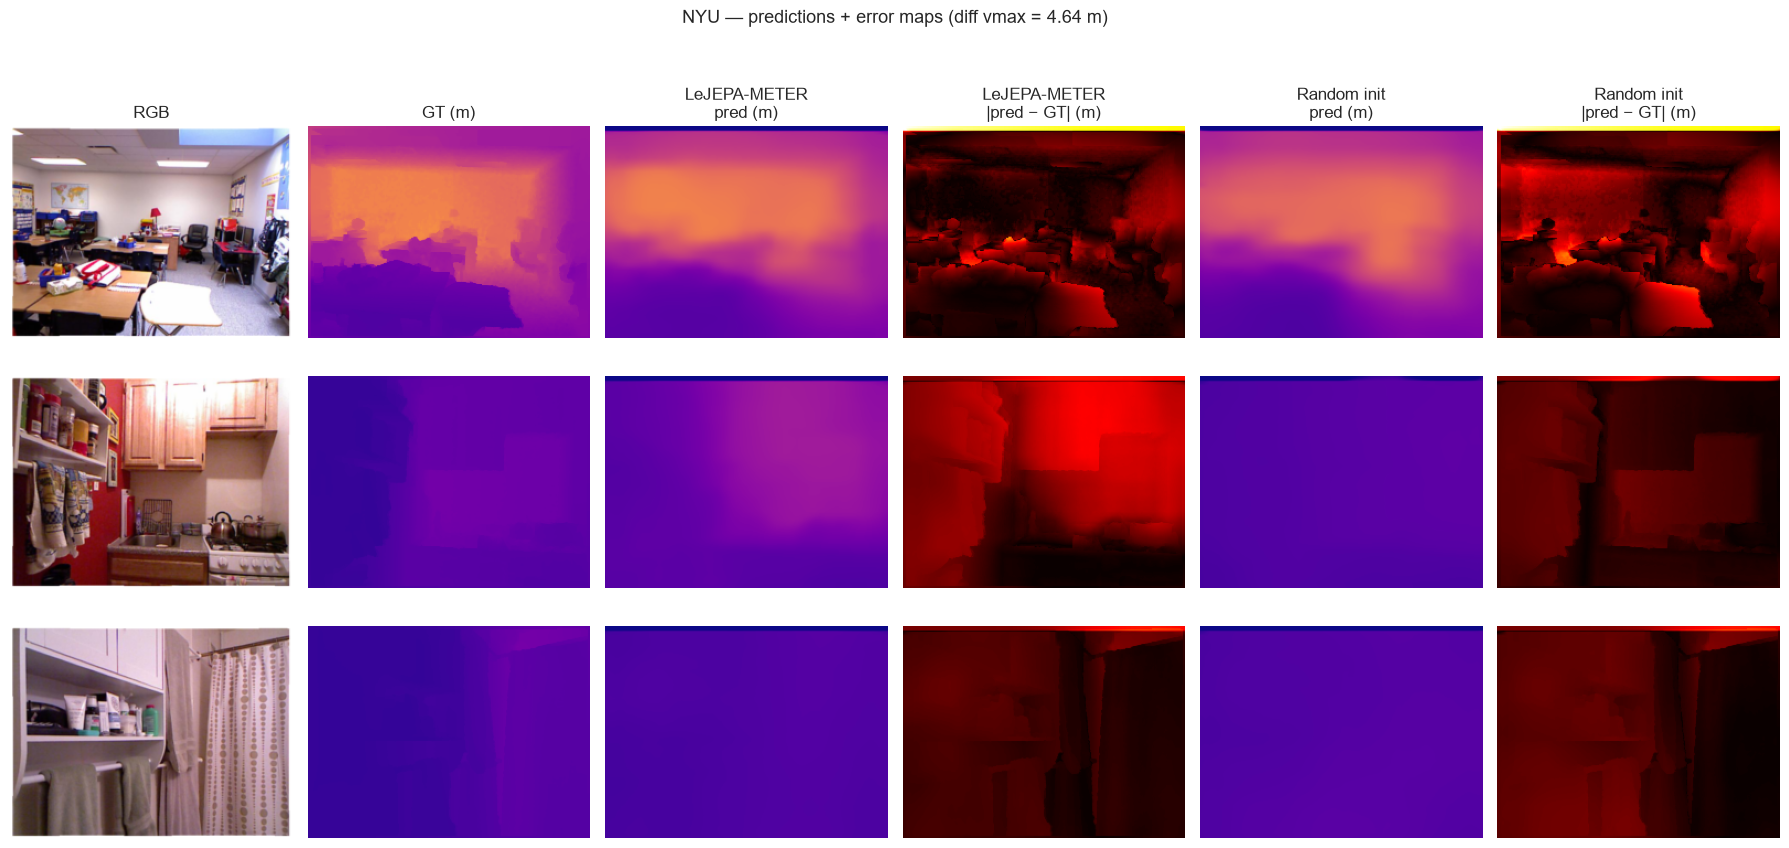

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\diff_maps_nyu_xs.pdf

=== DIFFERENCE MAPS — KITTI ===


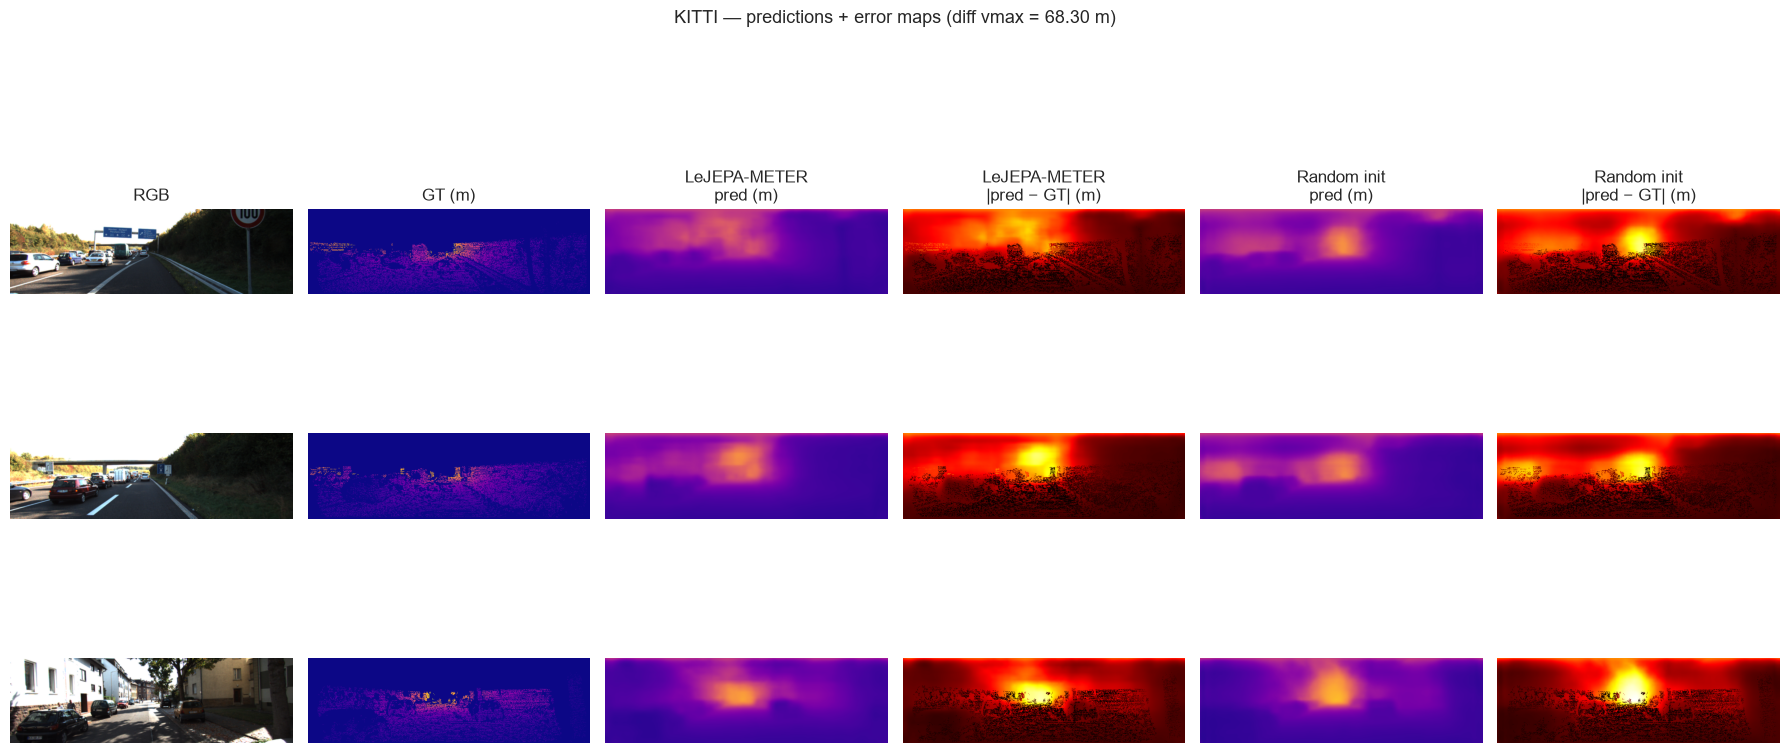

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\diff_maps_kitti_xs.pdf


In [12]:
for dataset in DATASETS:
    if dataset not in vis_loaders:
        continue
    variants_with_data = [v for v in VARIANTS if (v, dataset) in models]
    if len(variants_with_data) < 1:
        continue

    print(f"\n=== DIFFERENCE MAPS — {dataset.upper()} ===")

    batch = next(iter(vis_loaders[dataset]))
    rgb, depth_gt = batch
    rgb_show = denorm_rgb(rgb)

    if dataset == "nyu":
        scale, unit, vmax = 1/100.0, "m", 10.0
    else:
        scale, unit, vmax = 1.0, "m", 80.0

    gt_m = depth_gt.cpu() * scale

    preds, diffs = {}, {}
    for v in variants_with_data:
        pred = predict(models[(v, dataset)], rgb).cpu() * scale
        # Clamp coerente con il protocollo di valutazione del paper
        pred = pred.clamp(min=1e-3, max=vmax)
        gt_clamped = gt_m.clamp(min=1e-3, max=vmax)
        preds[v] = pred
        diffs[v] = (pred - gt_clamped).abs()

    # Vmax condiviso tra le due diff map per fair comparison
    diff_vmax = max(d.max().item() for d in diffs.values())
    diff_vmax = max(diff_vmax, 0.5)   # fondo minimo

    n_samples = rgb.shape[0]
    n_cols = 2 + 2 * len(variants_with_data)   # RGB | GT | (pred + diff) per variante
    fig, axes = plt.subplots(n_samples, n_cols, figsize=(3.0 * n_cols, 3.0 * n_samples))
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_m[i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
        axes[i, 1].set_title(f"GT ({unit})" if i == 0 else ""); axes[i, 1].axis("off")

        for k, v in enumerate(variants_with_data):
            col_p = 2 + 2 * k
            col_d = 3 + 2 * k
            axes[i, col_p].imshow(preds[v][i, 0].numpy(), cmap="plasma", vmin=0, vmax=vmax)
            axes[i, col_p].set_title(f"{VARIANTS[v]['label']}\npred ({unit})" if i == 0 else "")
            axes[i, col_p].axis("off")

            axes[i, col_d].imshow(diffs[v][i, 0].numpy(), cmap="hot", vmin=0, vmax=diff_vmax)
            axes[i, col_d].set_title(f"{VARIANTS[v]['label']}\n|pred − GT| ({unit})"
                                      if i == 0 else "")
            axes[i, col_d].axis("off")

    plt.suptitle(f"{dataset.upper()} — predictions + error maps "
                 f"(diff vmax = {diff_vmax:.2f} {unit})", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = Path(IMAGES_DIR) / f"diff_maps_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")


=== PCA — NYU ===


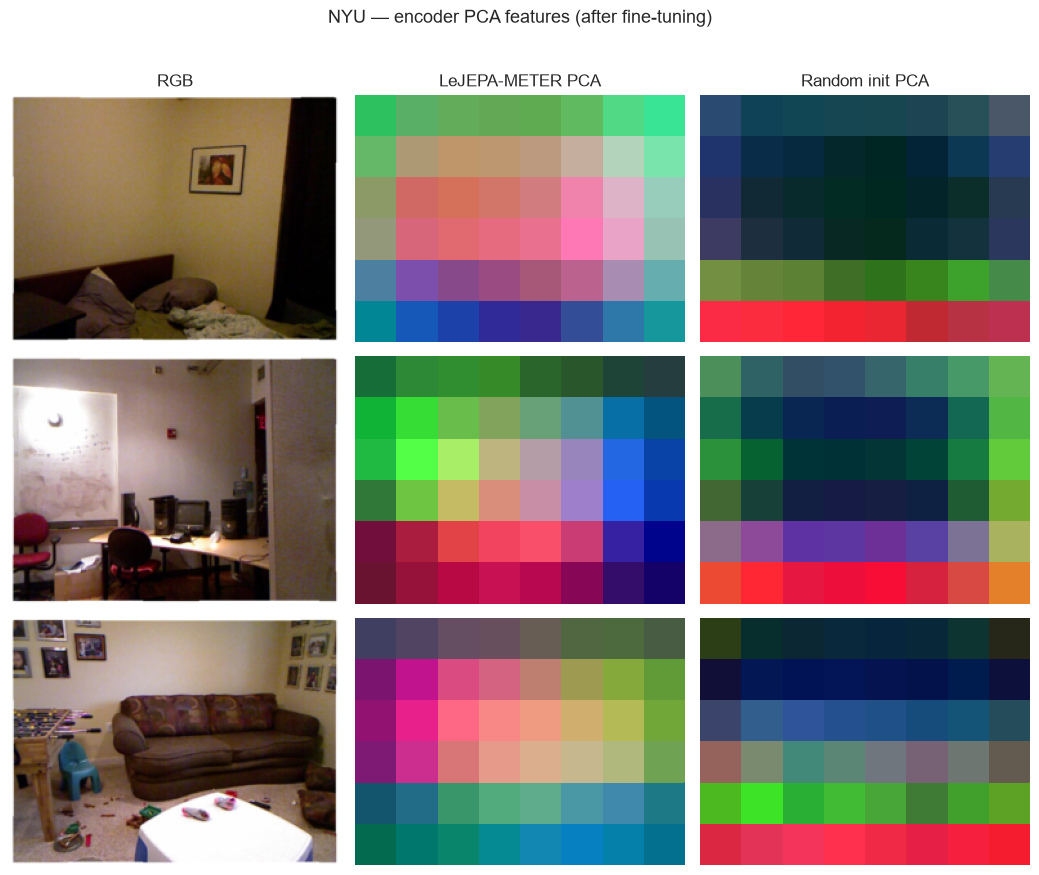

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\compare_pca_nyu_xs.pdf

=== PCA — KITTI ===


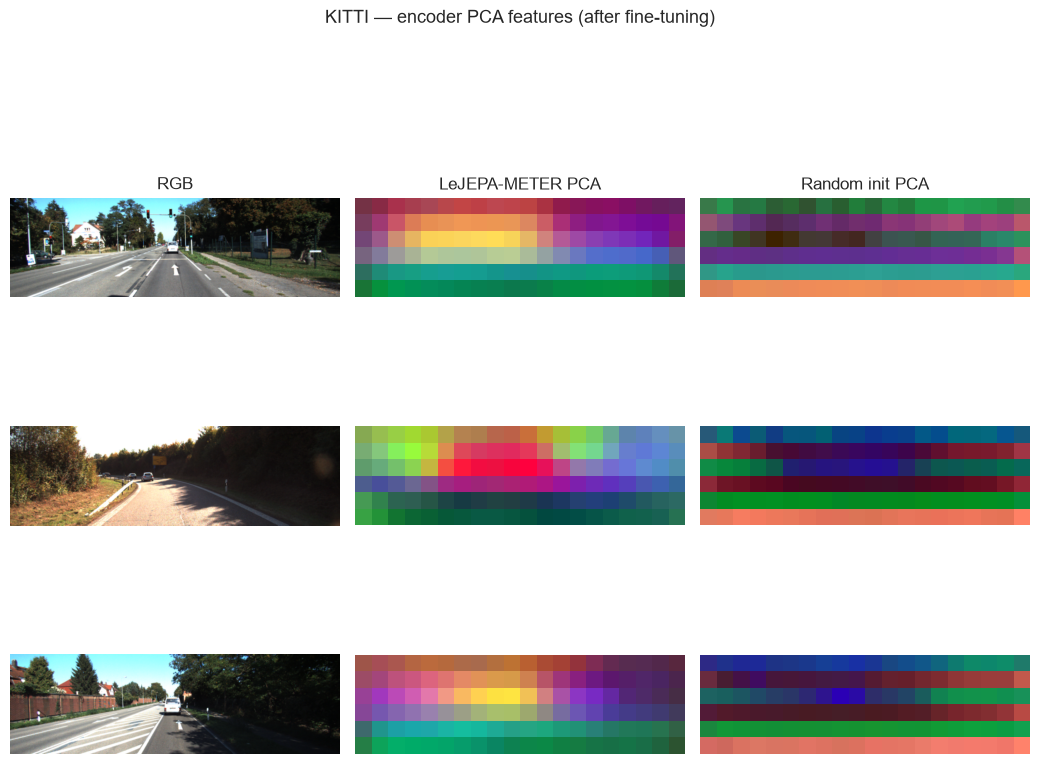

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\compare_pca_kitti_xs.pdf


In [13]:
for dataset in DATASETS:
    if dataset not in vis_loaders:
        continue
    variants_with_data = [v for v in VARIANTS if (v, dataset) in models]
    if not variants_with_data:
        continue

    print(f"\n=== PCA — {dataset.upper()} ===")

    batch = next(iter(vis_loaders[dataset]))
    rgb = batch[0] if isinstance(batch, (list, tuple)) else batch
    rgb = rgb.to(DEVICE)
    rgb_show = denorm_rgb(rgb)

    n_samples = rgb.shape[0]
    n_cols = 1 + len(variants_with_data)
    fig, axes = plt.subplots(n_samples, n_cols, figsize=(3.5 * n_cols, 3.0 * n_samples))
    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n_samples):
        axes[i, 0].imshow(rgb_show[i].permute(1, 2, 0).numpy())
        axes[i, 0].set_title("RGB" if i == 0 else ""); axes[i, 0].axis("off")

        for k, v in enumerate(variants_with_data):
            feat = extract_features(models[(v, dataset)], rgb[i:i+1], DEVICE)
            pca_img = features_to_pca(feat)
            axes[i, 1 + k].imshow(pca_img)
            axes[i, 1 + k].set_title(f"{VARIANTS[v]['label']} PCA" if i == 0 else "")
            axes[i, 1 + k].axis("off")

    plt.suptitle(f"{dataset.upper()} — encoder PCA features (after fine-tuning)", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = Path(IMAGES_DIR) / f"compare_pca_{dataset}_{ARCH_NAME}.pdf"
    plt.savefig(out, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"[OK] Saved → {out}")



=== PCA SCATTER — LeJEPA-METER | NYU ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (654, 192)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_scatter_lejepa_nyu_xs.pdf


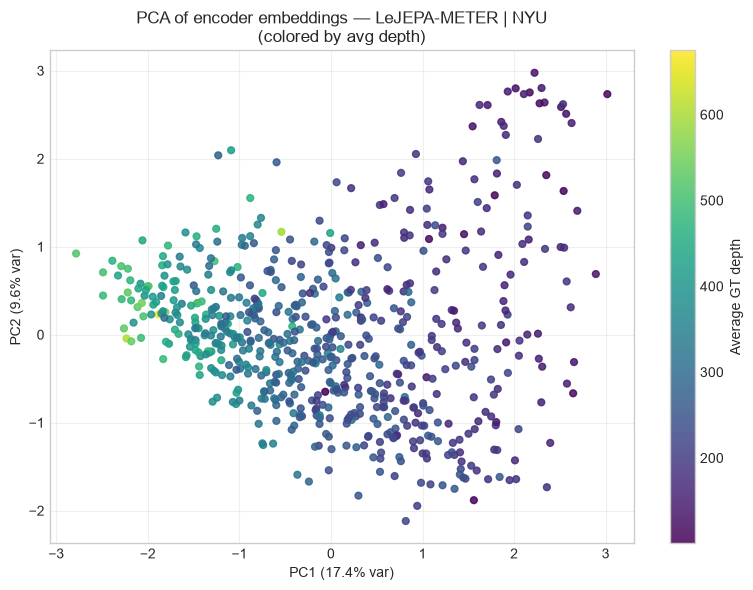


=== PCA SCATTER — Random init | NYU ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (654, 192)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_scatter_from_scratch_nyu_xs.pdf


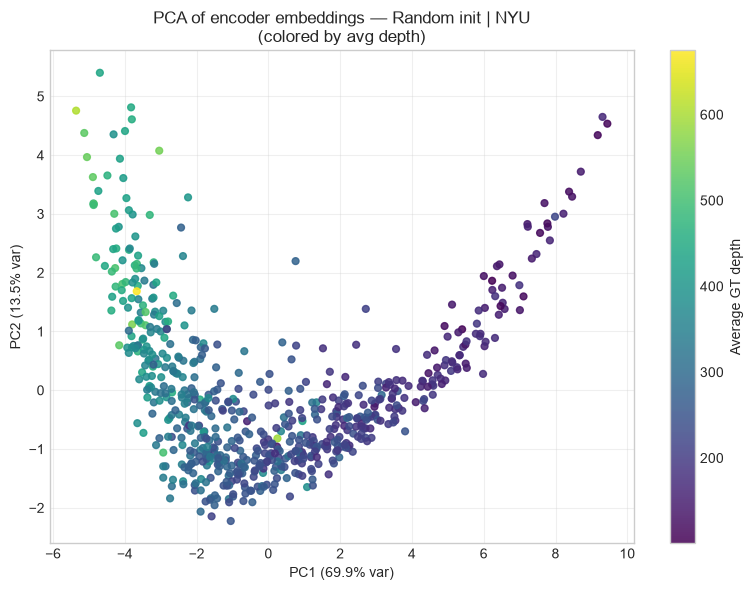


=== PCA SCATTER — LeJEPA-METER | KITTI ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (320, 192)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_scatter_lejepa_kitti_xs.pdf


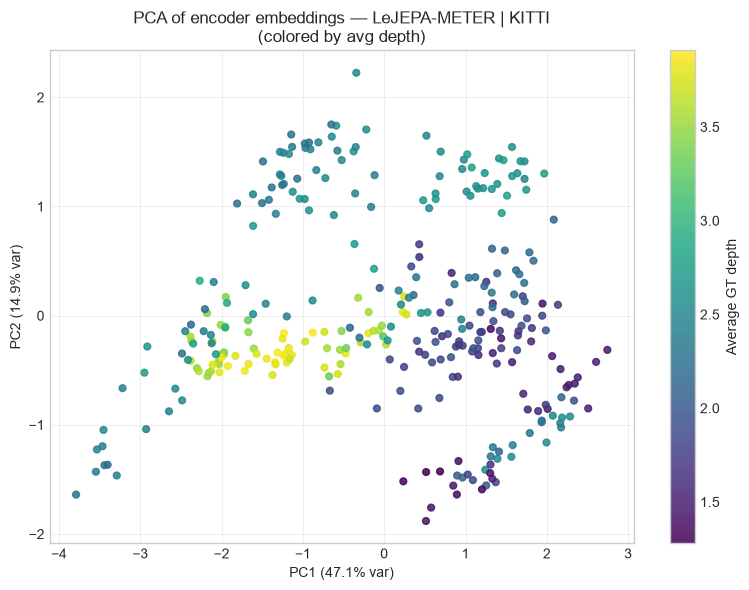


=== PCA SCATTER — Random init | KITTI ===

[INFO] Extracting embeddings for PCA scatter...
[INFO] Embeddings shape: (320, 192)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_scatter_from_scratch_kitti_xs.pdf


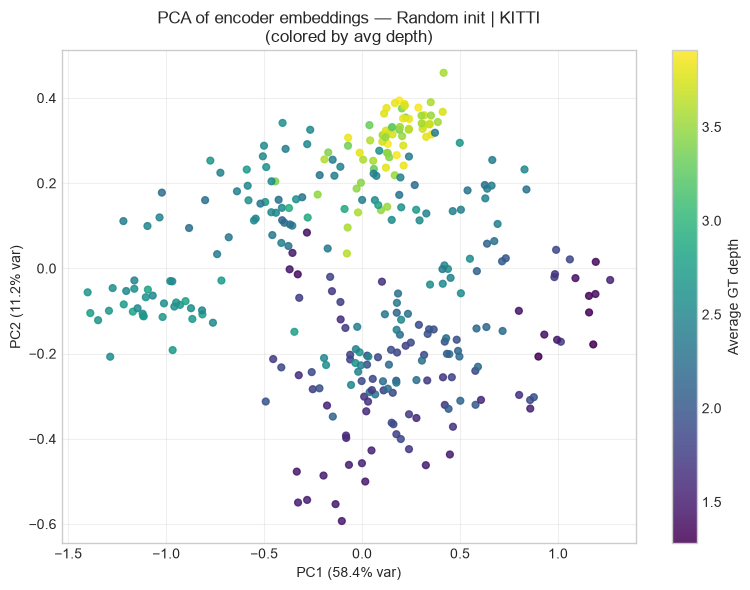

In [14]:
from src.evaluation import plot_pca_embeddings

for dataset in DATASETS:
    if dataset not in test_loaders:
        continue
    for variant_key in VARIANTS:
        if (variant_key, dataset) not in models:
            continue
        label = VARIANTS[variant_key]["label"]
        print(f"\n=== PCA SCATTER — {label} | {dataset.upper()} ===")
        plot_pca_embeddings(
            model         = models[(variant_key, dataset)],
            dataloader    = test_loaders[dataset],
            device        = DEVICE,
            save_path     = Path(IMAGES_DIR) / f"pca_scatter_{variant_key}_{dataset}_{ARCH_NAME}.pdf",
            max_batches   = 20,
            dataset_name  = dataset,      
            variant_label = label,        
        )

In [18]:
# Paper reference numbers (METER paper Table II — XXS row)
PAPER_REF = {
    "nyu"  : {"RMSE": 0.580, "AbsRel": 0.174, "Delta1": 0.744, "params_m": 0.71},
    "kitti": {"RMSE": 5.157, "AbsRel": 0.156, "Delta1": 0.782, "params_m": 0.71},
}

rows = []

# Paper reference rows (only if the arch is xxs — those are the published numbers)
if ARCH_NAME == "xxs":
    for dataset in DATASETS:
        ref = PAPER_REF[dataset]
        rows.append({
            "Dataset"        : dataset.upper(),
            "Variant"        : "Paper (Papa et al. 2024)",
            "RMSE"           : f"{ref['RMSE']:.4f}",
            "AbsRel"         : f"{ref['AbsRel']:.4f}",
            "Delta1"         : f"{ref['Delta1']:.4f}",
            "Params (M)"     : f"{ref['params_m']:.2f}",
            "Latency (ms)"   : "-",
            "Train time (s)" : "-",
        })

# Our runs
for dataset in DATASETS:
    eff = efficiency.get(dataset)
    lat = f"{eff['latency_ms']:.2f}" if eff else "-"
    for variant_key, vinfo in VARIANTS.items():
        key = (variant_key, dataset)
        if key not in results:
            continue
        r = results[key]
        rows.append({
            "Dataset"        : dataset.upper(),
            "Variant"        : vinfo["label"],
            "RMSE"           : f"{r['RMSE']:.4f}",
            "AbsRel"         : f"{r['AbsRel']:.4f}",
            "Delta1"         : f"{r['Delta1']:.4f}",
            "Params (M)"     : f"{eff['params_m']:.2f}" if eff else "-",
            "Latency (ms)"   : lat,
            "Train time (s)" : f"{r['train_time_sec']:.0f}" if r['train_time_sec'] else "-",
        })

# Compute Δ RMSE (LeJEPA - random init) per dataset
delta_rows = []
for dataset in DATASETS:
    if ("lejepa", dataset) in results and ("from_scratch", dataset) in results:
        d_rmse   = results[("lejepa", dataset)]["RMSE"]   - results[("from_scratch", dataset)]["RMSE"]
        d_absrel = results[("lejepa", dataset)]["AbsRel"] - results[("from_scratch", dataset)]["AbsRel"]
        d_delta1 = results[("lejepa", dataset)]["Delta1"] - results[("from_scratch", dataset)]["Delta1"]
        delta_rows.append({
            "Dataset"        : dataset.upper(),
            "Variant"        : "Δ (LeJEPA − Random init)",
            "RMSE"           : f"{d_rmse:+.4f}",
            "AbsRel"         : f"{d_absrel:+.4f}",
            "Delta1"         : f"{d_delta1:+.4f}",
            "Params (M)"     : "-",
            "Latency (ms)"   : "-",
            "Train time (s)" : "-",
        })

table = pd.DataFrame(rows + delta_rows)
print("=== FINAL COMPARISON TABLE ===\n")
print(table.to_string(index=False))

csv_path = Path(OUTPUT_DIR) / "csv" / f"compare_full_{ARCH_NAME}.csv"
table.to_csv(csv_path, index=False)
print(f"\n[OK] CSV saved → {csv_path}")

# Headline summary
print("\n=== HEADLINE ===")
for d_row in delta_rows:
    rmse_str = d_row["RMSE"]
    sign = float(rmse_str)
    verdict = "✅ LeJEPA helps" if sign < 0 else ("⚠️  LeJEPA hurts" if sign > 0 else "≈ Tied")
    print(f"  {d_row['Dataset']:7s}  ΔRMSE = {rmse_str}  →  {verdict}")


=== FINAL COMPARISON TABLE ===

Dataset                  Variant    RMSE  AbsRel  Delta1 Params (M) Latency (ms) Train time (s)
    NYU             LeJEPA-METER  0.8522  0.1952  0.6971       1.45        13.38              -
    NYU              Random init  0.8628  0.1996  0.6864       1.45        13.38              -
  KITTI             LeJEPA-METER  4.6835  0.1200  0.8465       1.45        14.26              -
  KITTI              Random init  4.6741  0.1143  0.8587       1.45        14.26              -
    NYU Δ (LeJEPA − Random init) -0.0106 -0.0044 +0.0106          -            -              -
  KITTI Δ (LeJEPA − Random init) +0.0094 +0.0057 -0.0122          -            -              -

[OK] CSV saved → C:\Users\andre\Desktop\CV-project-25-26\output\csv\compare_full_xs.csv

=== HEADLINE ===
  NYU      ΔRMSE = -0.0106  →  ✅ LeJEPA helps
  KITTI    ΔRMSE = +0.0094  →  ⚠️  LeJEPA hurts


=== TRAINING COST vs ACCURACY ===
[INFO] Estimated SSL time (nyu): 50 epochs × 240 s = 12000 s
[INFO] Estimated SSL time (kitti): 50 epochs × 240 s = 12000 s
  SSL NYU: 200.0 min (3.33 h)
  SSL KITTI: 200.0 min (3.33 h)



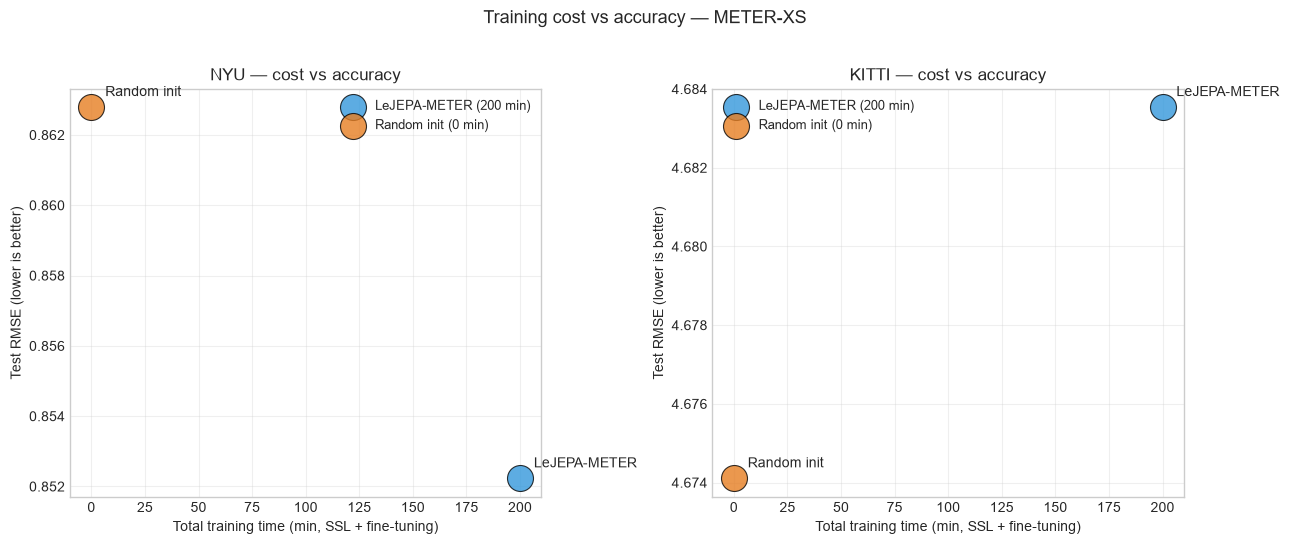

[OK] Saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\cost_vs_accuracy_xs.pdf

=== COST-BENEFIT SUMMARY ===
  NYU     Extra cost = +200.0 min  |  RMSE gain = +0.0106  (+1.2% relative)
  KITTI   Extra cost = +200.0 min  |  RMSE gain = -0.0094  (-0.2% relative)


In [19]:
print("=== TRAINING COST vs ACCURACY ===")

# SSL pre-training time per dataset (if logged from main.ipynb step 4D)
ssl_pretrain_time = {}   # dataset -> seconds

for dataset in DATASETS:
    ssl_metrics_path = Path(JSON_DIR) / f"pretrain_metrics_{dataset}_{ARCH_NAME}.json"
    if ssl_metrics_path.exists():
        ssl_meta = load_dict_from_json(ssl_metrics_path)
        ssl_pretrain_time[dataset] = float(ssl_meta.get("train_time_sec", 0.0))
        continue

    # Fallback: estimate from Lightning CSV logger.
    # Self-contained CSV lookup so this cell does not depend on helper functions
    # defined in later cells (the original find_logger_csv was defined further down).
    def _latest_ssl_csv(pattern):
        m = list(Path(OUTPUT_DIR).glob(f"{pattern}/version_*/metrics.csv"))
        if not m:
            m = [p for p in Path(OUTPUT_DIR).rglob("metrics.csv") if pattern in str(p)]
        return max(m, key=lambda p: p.stat().st_mtime) if m else None

    ssl_csv = _latest_ssl_csv(f"ssl_{dataset}_log") or _latest_ssl_csv("ssl_log")
    if ssl_csv is not None:
        try:
            ssl_df = pd.read_csv(ssl_csv)
            n_epochs = int(ssl_df["epoch"].dropna().max() + 1) if "epoch" in ssl_df.columns else 0
            est = n_epochs * 240.0     # rough estimate: 4 min/epoch
            ssl_pretrain_time[dataset] = est
            print(f"[INFO] Estimated SSL time ({dataset}): {n_epochs} epochs × 240 s = {est:.0f} s")
            continue
        except Exception:
            pass

    ssl_pretrain_time[dataset] = 0.0
    print(f"[WARN] No SSL pretrain log for {dataset} — using 0 s in cost plot")

for dataset, t in ssl_pretrain_time.items():
    print(f"  SSL {dataset.upper()}: {t/60:.1f} min ({t/3600:.2f} h)")
print()

# Build the scatter plot
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.5 * len(DATASETS), 5.5), squeeze=False)
axes = axes.flatten()

for ax_idx, dataset in enumerate(DATASETS):
    ax = axes[ax_idx]
    for variant_key, vinfo in VARIANTS.items():
        if (variant_key, dataset) not in results:
            continue
        r = results[(variant_key, dataset)]
        ft_time = r["train_time_sec"]

        # Total cost: SSL pre-training counts only for LeJEPA
        total_cost_sec = ft_time + (ssl_pretrain_time.get(dataset, 0.0) if variant_key == "lejepa" else 0.0)
        total_cost_min = total_cost_sec / 60.0

        ax.scatter(total_cost_min, r["RMSE"],
                   s=350, alpha=0.8,
                   color=vinfo["color"], edgecolor="black", linewidth=0.8,
                   label=f"{vinfo['label']} ({total_cost_min:.0f} min)")
        ax.annotate(vinfo["label"], (total_cost_min, r["RMSE"]),
                    textcoords="offset points", xytext=(10, 8), fontsize=10)

    ax.set_xlabel("Total training time (min, SSL + fine-tuning)")
    ax.set_ylabel("Test RMSE (lower is better)")
    ax.set_title(f"{dataset.upper()} — cost vs accuracy")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)

plt.suptitle(f"Training cost vs accuracy — METER-{ARCH_NAME.upper()}", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])

out = Path(IMAGES_DIR) / f"cost_vs_accuracy_{ARCH_NAME}.pdf"
plt.savefig(out, dpi=140, bbox_inches="tight")
plt.show()
print(f"[OK] Saved → {out}")

# How much does SSL cost relative to the gain? Final number for the report
print("\n=== COST-BENEFIT SUMMARY ===")
for dataset in DATASETS:
    if ("lejepa", dataset) in results and ("from_scratch", dataset) in results:
        lej = results[("lejepa", dataset)]
        rnd = results[("from_scratch", dataset)]

        ft_diff = lej["train_time_sec"] - rnd["train_time_sec"]
        total_extra_cost = ssl_pretrain_time.get(dataset, 0.0) + ft_diff
        rmse_gain = rnd["RMSE"] - lej["RMSE"]                # positive = LeJEPA performs better

        print(f"  {dataset.upper():6s}  Extra cost = {total_extra_cost/60:+.1f} min  "
              f"|  RMSE gain = {rmse_gain:+.4f}  "
              f"({rmse_gain/rnd['RMSE']*100:+.1f}% relative)")

  RELATIVE IMPROVEMENT — LeJEPA vs Random Init

━━━ NYU ━━━
  RMSE     Random=0.8628  LeJEPA=0.8522  Δabs=+0.0106m  Δrel=++1.22%  ✅ LeJEPA helps
  AbsRel   Random=0.1996  LeJEPA=0.1952  Δabs=+0.0044  Δrel=++2.20%  ✅ LeJEPA helps
  Delta1   Random=0.6864  LeJEPA=0.6971  Δabs=+0.0106  Δrel=++1.55%  ✅ LeJEPA helps

━━━ KITTI ━━━
  RMSE     Random=4.6741  LeJEPA=4.6835  Δabs=-0.0094m  Δrel=-0.20%  ≈ tied
  AbsRel   Random=0.1143  LeJEPA=0.1200  Δabs=-0.0057  Δrel=-4.97%  ⚠️  LeJEPA hurts
  Delta1   Random=0.8587  LeJEPA=0.8465  Δabs=-0.0122  Δrel=-1.42%  ⚠️  LeJEPA hurts

[OK] CSV saved → C:\Users\andre\Desktop\CV-project-25-26\output\csv\improvement_summary_xs.csv


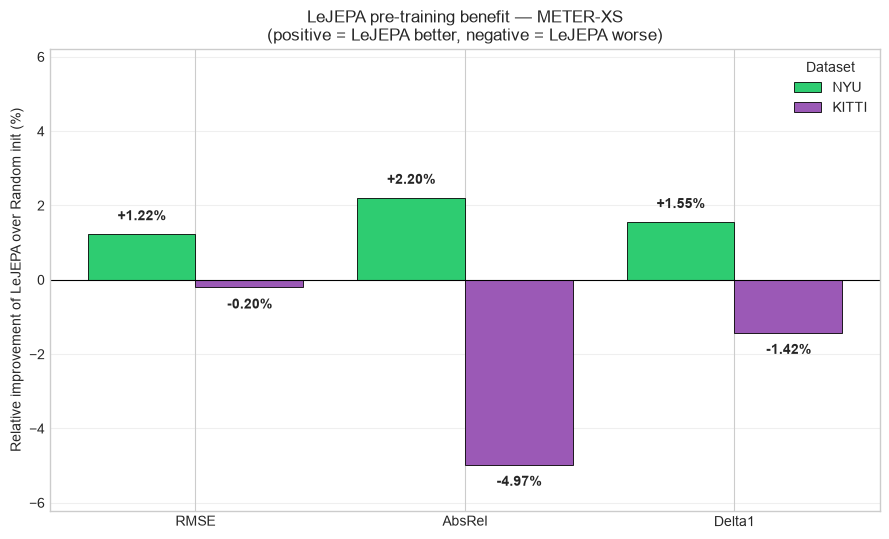

[OK] Chart saved → C:\Users\andre\Desktop\CV-project-25-26\output\images\improvement_summary_xs.pdf


In [20]:
print("=" * 70)
print("  RELATIVE IMPROVEMENT — LeJEPA vs Random Init")
print("=" * 70)
print()

# Direction-aware sign convention:
#  - RMSE, AbsRel: lower is better → improvement = (random - lejepa) / random * 100
#  - Delta1      : higher is better → improvement = (lejepa - random) / random * 100
METRICS = [
    ("RMSE",   "lower",  "m"),
    ("AbsRel", "lower",  ""),
    ("Delta1", "higher", ""),
]

improvement_rows = []
chart_data = {}   # {dataset: {metric: rel_delta_pct}}

for dataset in DATASETS:
    if (("lejepa", dataset) not in results or
        ("from_scratch", dataset) not in results):
        print(f"[SKIP {dataset.upper()}] — missing one of the two variants")
        continue

    lej = results[("lejepa",       dataset)]
    rnd = results[("from_scratch", dataset)]

    print(f"━━━ {dataset.upper()} ━━━")
    chart_data[dataset] = {}
    for metric_name, direction, unit in METRICS:
        v_lej = lej[metric_name]
        v_rnd = rnd[metric_name]
        if direction == "lower":
            abs_delta = v_rnd - v_lej
            rel_delta = abs_delta / v_rnd * 100
        else:
            abs_delta = v_lej - v_rnd
            rel_delta = abs_delta / v_rnd * 100

        sign_str = "+" if rel_delta >= 0 else ""
        verdict  = "✅ LeJEPA helps" if rel_delta > 0.5 else (
                   "⚠️  LeJEPA hurts" if rel_delta < -0.5 else
                   "≈ tied")

        print(f"  {metric_name:7s}  Random={v_rnd:.4f}  LeJEPA={v_lej:.4f}  "
              f"Δabs={abs_delta:+.4f}{unit}  Δrel={sign_str}{rel_delta:+.2f}%  {verdict}")

        improvement_rows.append({
            "Dataset"      : dataset.upper(),
            "Metric"       : metric_name,
            "Random init"  : f"{v_rnd:.4f}",
            "LeJEPA"       : f"{v_lej:.4f}",
            "Δ abs"        : f"{abs_delta:+.4f}",
            "Δ relative"   : f"{sign_str}{rel_delta:+.2f}%",
            "Verdict"      : verdict,
        })
        chart_data[dataset][metric_name] = rel_delta
    print()

# Save CSV for the report
if improvement_rows:
    imp_df = pd.DataFrame(improvement_rows)
    out_csv = Path(OUTPUT_DIR) / "csv" / f"improvement_summary_{ARCH_NAME}.csv"
    imp_df.to_csv(out_csv, index=False)
    print(f"[OK] CSV saved → {out_csv}")


# ============================================================
# Grouped bar chart: relative improvement (%) per metric × dataset
# ============================================================
if chart_data:
    metrics_to_plot = [m[0] for m in METRICS]
    datasets_to_plot = list(chart_data.keys())
    n_metrics  = len(metrics_to_plot)
    n_datasets = len(datasets_to_plot)

    x       = np.arange(n_metrics)
    width   = 0.8 / n_datasets
    palette = {"nyu": "#2ecc71", "kitti": "#9b59b6"}  

    fig, ax = plt.subplots(figsize=(9, 5.5))

    for i, dataset in enumerate(datasets_to_plot):
        vals = [chart_data[dataset].get(m, 0.0) for m in metrics_to_plot]
        offsets = x + (i - (n_datasets - 1) / 2) * width
        bars = ax.bar(offsets, vals, width,
                      color=palette.get(dataset, "#888888"),
                      edgecolor="black", linewidth=0.6,
                      label=dataset.upper())
        # Numeric labels on top/bottom of each bar
        for bar, v in zip(bars, vals):
            h = bar.get_height()
            va = "bottom" if h >= 0 else "top"
            offset = 0.3 if h >= 0 else -0.3
            ax.text(bar.get_x() + bar.get_width() / 2, h + offset,
                    f"{v:+.2f}%", ha="center", va=va, fontsize=10,
                    fontweight="bold")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_to_plot)
    ax.set_ylabel("Relative improvement of LeJEPA over Random init (%)")
    ax.set_title(f"LeJEPA pre-training benefit — METER-{ARCH_NAME.upper()}\n"
                 "(positive = LeJEPA better, negative = LeJEPA worse)",
                 fontsize=12)
    ax.legend(loc="best", title="Dataset")
    ax.grid(axis="y", alpha=0.3)

    # Symmetric y-limit for clean visualization
    all_vals = [v for d in chart_data.values() for v in d.values()]
    ymax = max(abs(min(all_vals)), abs(max(all_vals))) * 1.25
    ymax = max(ymax, 5.0)   # at least ±5%
    ax.set_ylim(-ymax, ymax)

    plt.tight_layout()
    out_pdf = Path(IMAGES_DIR) / f"improvement_summary_{ARCH_NAME}.pdf"
    plt.savefig(out_pdf, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[OK] Chart saved → {out_pdf}")